Objective

The main objective of this project is to develop an Artificial Neural Network (ANN) model to predict diabetes progression using the Diabetes dataset available in the Scikit-learn library. The project aims to understand how different patient health features influence diabetes progression by analyzing the dataset and identifying patterns through Exploratory Data Analysis (EDA).

The project involves loading and preprocessing the dataset, checking for missing values, normalizing the input features, and visualizing the relationships between the features and the target variable. A suitable ANN architecture will be designed and trained using the processed data. The model's performance will be evaluated using Mean Squared Error (MSE) and R² score. Finally, different network architectures, activation functions, and hyperparameters will be experimented with to improve model performance and compare the results.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam


In [2]:
diabetes = load_diabetes()

df = pd.DataFrame(
    diabetes.data,
    columns=diabetes.feature_names
)

df["target"] = diabetes.target


df.head()


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
print("Dataset shape:", df.shape)
print("\nColumns in the dataset:")
print(df.columns.tolist())
df.info()
df.describe()


Dataset shape: (442, 11)

Columns in the dataset:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'target']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


In [4]:

print("Missing values in each column:")
print(df.isnull().sum())
print("\nNumber of duplicate rows:", df.duplicated().sum())


Missing values in each column:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Number of duplicate rows: 0


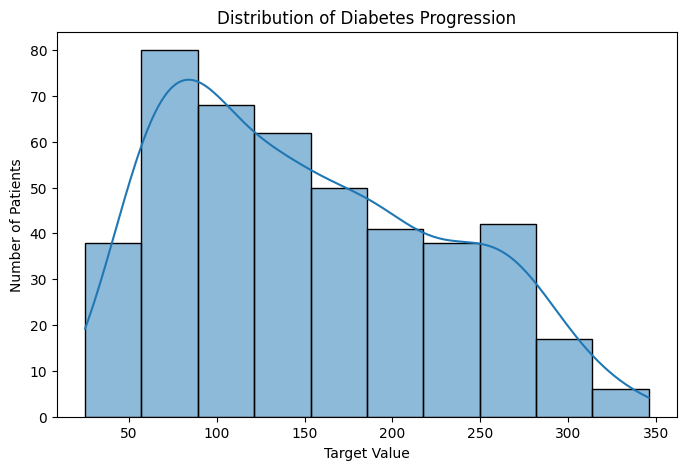

In [5]:

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="target", kde=True)

plt.title("Distribution of Diabetes Progression")
plt.xlabel("Target Value")
plt.ylabel("Number of Patients")

plt.show()


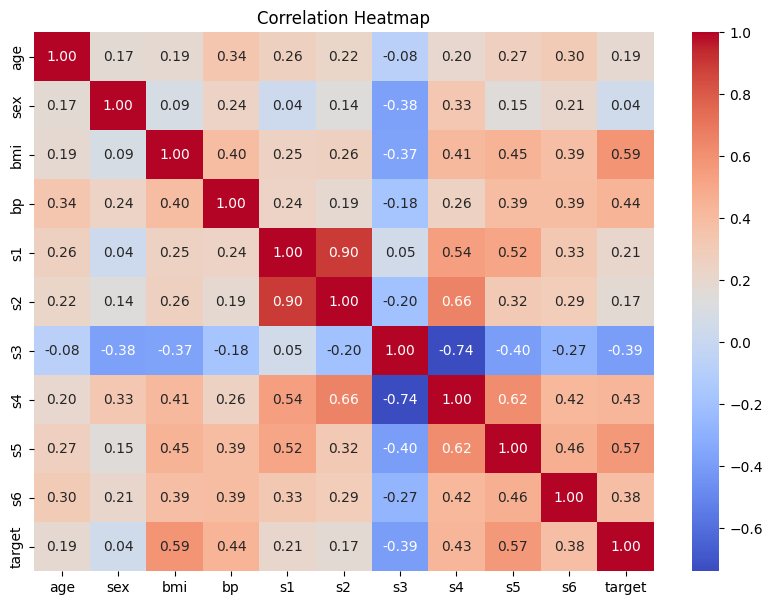

In [6]:

plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()


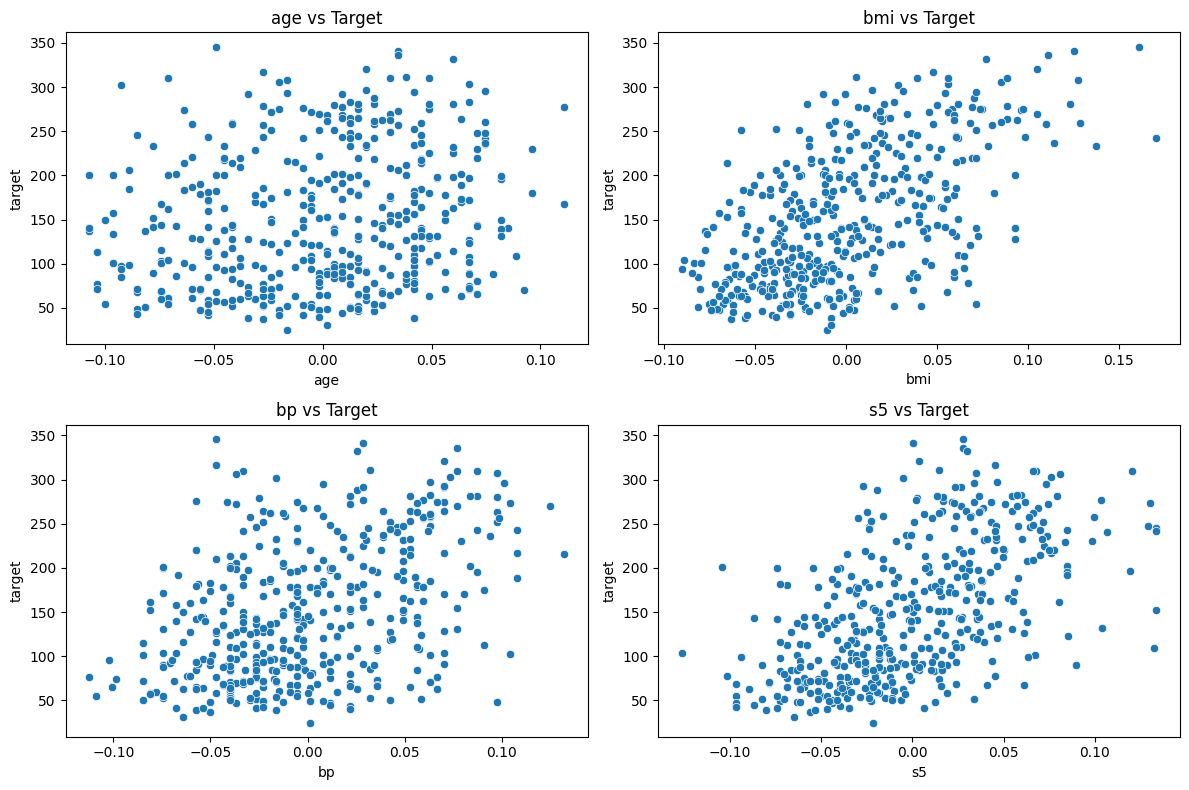

In [7]:

features = ["age", "bmi", "bp", "s5"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(features, axes.flatten()):
    sns.scatterplot(
        data=df,
        x=feature,
        y="target",
        ax=ax
    )
    ax.set_title(f"{feature} vs Target")

plt.tight_layout()
plt.show()


In [8]:

X = df.drop("target", axis=1)

y = df["target"]

print("Input data shape:", X.shape)
print("Target data shape:", y.shape)


Input data shape: (442, 10)
Target data shape: (442,)


In [9]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])


Training records: 353
Testing records: 89


In [10]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature normalization completed.")


Feature normalization completed.


In [11]:

model = Sequential([
    Dense(16, activation="relu", input_shape=(10,)),
    Dense(1, activation="linear")
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 193 (772.00 B)

 Trainable params: 193 (772.00 B)

 Non-trainable params: 0 (0.00 B)

In [12]:

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    epochs=200,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - loss: 31391.6055 - val_loss: 22361.8047
Epoch 2/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 31284.5879 - val_loss: 22288.8848
Epoch 3/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 31180.9922 - val_loss: 22214.7441
Epoch 4/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 31076.5039 - val_loss: 22142.2051
Epoch 5/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 30972.8262 - val_loss: 22068.6582
Epoch 6/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 30868.0566 - val_loss: 21993.0957
Epoch 7/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 30758.1055 - val_loss: 21916.3125
Epoch 8/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 30649.3008 - val_loss: 21835.8418
Epoch 9/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 30529.7598 - val_loss: 21755.8008
Epoch 10/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 30410.6387 - val_loss: 21667.7051
Epoch 11/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss

In [13]:

y_pred = model.predict(X_test_scaled).flatten()

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", round(mse, 2))
print("R2 Score:", round(r2, 3))


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step 
Mean Squared Error: 4388.22
R2 Score: 0.172


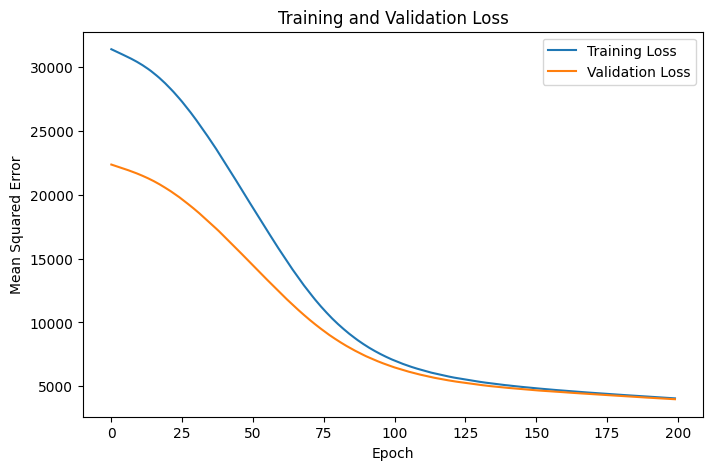

In [14]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()

plt.show()


In [15]:

improved_model = Sequential([
    Dense(32, activation="relu", input_shape=(10,)),
    Dense(16, activation="relu"),
    Dense(1, activation="linear")
])

improved_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mean_squared_error"
)

improved_history = improved_model.fit(
    X_train_scaled,
    y_train,
    epochs=200,
    batch_size=16,
    validation_split=0.2,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=20,
            restore_best_weights=True
        )
    ],
    verbose=1
)


Epoch 1/200


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 31574.3906 - val_loss: 22417.6152
Epoch 2/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 31392.6602 - val_loss: 22252.5996
Epoch 3/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 31208.8086 - val_loss: 22075.1875
Epoch 4/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 30991.7266 - val_loss: 21853.4141
Epoch 5/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 30716.3340 - val_loss: 21563.7852
Epoch 6/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 30339.0918 - val_loss: 21193.4375
Epoch 7/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 29841.7266 - val_loss: 20710.2324
Epoch 8/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 29180.7012 - val_loss: 20109.0801
Epoch 9/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 28330.1270 - val_loss: 19355.6484
Epoch 10/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 27259.8555 - val_loss: 18457.1094
Epoch 11/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 25925.5762 - val_los

In [16]:

improved_pred = improved_model.predict(X_test_scaled).flatten()

improved_mse = mean_squared_error(y_test, improved_pred)
improved_r2 = r2_score(y_test, improved_pred)


results = pd.DataFrame({
    "Model": ["Baseline ANN", "Improved ANN"],
    "MSE": [mse, improved_mse],
    "R2 Score": [r2, improved_r2]
})

results


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


,Model,MSE,R2 Score
0,Baseline ANN,4388.223258,0.171745
1,Improved ANN,2897.113906,0.453184


Conclusion

In this project, I developed an Artificial Neural Network (ANN) model to predict diabetes progression using the Scikit-learn Diabetes dataset. I started by loading the dataset, examining its structure, checking for missing values and duplicates, and performing data preprocessing. Exploratory Data Analysis (EDA) was carried out using visualizations to understand the distribution of the target variable and the relationships between the input features and the target.

After preprocessing, I divided the dataset into training and testing sets and normalized the input features using StandardScaler. I then built and trained an ANN model with a hidden layer, using ReLU activation, a linear output layer, the Adam optimizer, and Mean Squared Error as the loss function. The model was evaluated using MSE and R² score to understand its prediction performance.

To further improve the model, I experimented with a different network architecture by adding another hidden layer and increasing the number of neurons. I compared the baseline and improved models using the same testing dataset to understand how architectural changes affect performance. Through this project, I gained practical experience in data preprocessing, visualization, ANN development, model evaluation, and hyperparameter experimentation. The project also helped me understand the importance of evaluating and comparing different models to identify a suitable approach for predicting diabetes progression.